# Dragging a Brownian Particle: Learning the Optimal Protocol

A bead sits in a harmonic optical trap, $U(x,\lambda)=\tfrac12(x-\lambda)^2$, in a viscous fluid at temperature
$T$ (units $k=\gamma=k_BT=1$). We move the trap centre from $0$ to $\Delta\lambda=5$ in time $t_f=2$. Moving a
harmonic trap leaves its free energy unchanged, so all the work is dissipated. **Which protocol $\lambda(t)$ costs
the least mean work?**

The answer, due to Schmiedl and Seifert (PRL 98, 108301, 2007), is not "drag at constant speed". The optimal
protocol **jumps** at both ends. Here a reinforcement-learning agent has to find that out from noisy work
samples alone. A second agent is then allowed to *measure the bead* before every move, and we ask what the
measurement is worth.

The environment is linear–Gaussian and the cost is quadratic, so every RL result below has an exact counterpart:
a linear solve for the open-loop problem, and a backward Bellman recursion for the feedback problem.

### The MDP

The protocol has $N=20$ steps of $\Delta t=t_f/N$. Action $k$ jumps the trap to $\lambda_k$ and holds it there. At
$t_f$ the trap is jumped to $\Delta\lambda$, which is forced. Between jumps the bead follows the exact
Ornstein–Uhlenbeck step $x_k=\lambda_k+(x_{k-1}-\lambda_k)\,a+\sqrt{1-a^2}\,\xi_k$, with $a=e^{-\Delta t}$, so there
is no time-step error. A jump at fixed $x$ costs $w_k=U(x_{k-1},\lambda_k)-U(x_{k-1},\lambda_{k-1})$.

| | open loop (steps 2–3) | feedback (steps 4–5) |
|---|---|---|
| state $s_k$ | the step index $k$ alone | $(k,\ x_{k-1},\ \lambda_{k-1})$, measured before acting |
| action $a_k$ | $\lambda_k\in\mathbb R$ | $\lambda_k\in\mathbb R$ |
| transition | exact OU step, $x_0\sim\mathcal N(0,1)$ | the same |
| reward | $r_k=-w_k$ | $r_k=-w_k$ |
| episode | $N$ actions, then the forced jump to $\Delta\lambda$ | the same |

The open-loop agent never sees $x$. Its environment is stochastic, but it has nothing to condition on, so its
best policy is a fixed sequence of $\lambda$'s. The feedback agent sees $x$, and that is where the state space
earns its keep.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import trap, agents

N, TF, DL = 20, 2.0, 5.0
DT = TF / N
A_OU = trap.ou_a(N, TF)
# one colour per entity, used in every figure
C_OPEN, C_FB, C_FQI, C_LIN, C_INK = '#2a78d6', '#eb6834', '#1baf7a', '#8a8a85', '#222222'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6, 'legend.frameon': False})

CHECKS = []
def check(name, ok, detail=''):
    CHECKS.append((name, bool(ok)))
    print(f"CHECK {name}: {'PASS' if ok else 'FAIL'}   {detail}")

def stairs(ax, u, dl=DL, **kw):
    # protocol as held values, with lam = 0 before t = 0 and lam = dl after tf
    n = len(u); edges = np.concatenate([[-0.25], TF / n * np.arange(n + 1), [TF + 0.25]])
    ax.stairs(np.concatenate([[0.0], u, [dl]]), edges, baseline=None, **kw)

def ss_curve(ax, **kw):
    c = DL / (TF + 2)
    ax.plot([-0.25, 0, 0, TF, TF, TF + 0.25], [0, 0, c, c * (TF + 1), DL, DL], **kw)

## Headline: what the agents learned

**Top.** The exact optimum $u^*$ (black steps) is a ramp with a jump at each end, and it sits on the
Schmiedl–Seifert continuum protocol (dashed). The REINFORCE agent (blue) starts from the constant-speed ramp
(gray) and finds both jumps. The thin orange lines are three single runs of the exact *feedback* policy. Each
reacts to its own bead, and on average they reproduce $u^*$ (step 4 explains why).

**Bottom.** Learning curves, using the *exact* mean work of each agent's current deterministic policy. That is
computable here, so the curves carry no evaluation noise. The diamonds are the Polyak averages of the second
half of training. Averaging the iterates removes most of the optimizer noise, which keeps the current iterate
hovering above the optimum. Open-loop REINFORCE runs for 5 seeds from the ramp.
Feedback REINFORCE runs for 4 seeds and starts at $u^*$, which is the best any state-blind policy can do. The
measurement then lets it go below that floor.

training: 26.4 s


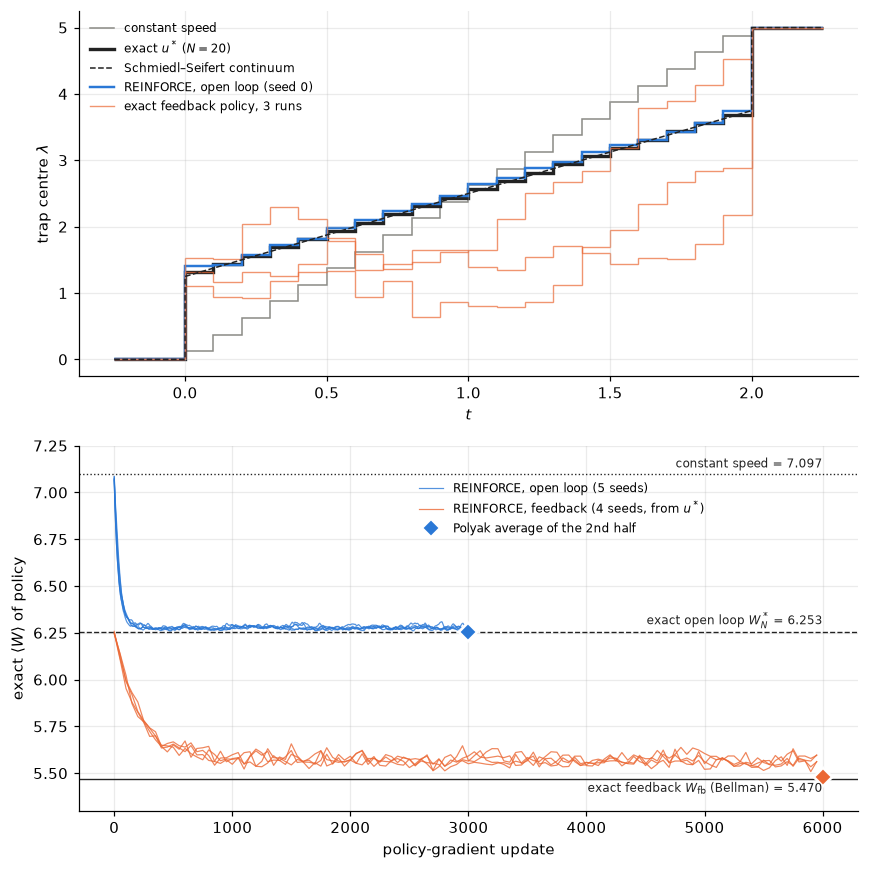

In [2]:
t0 = time.time()
u_star, W_star_N = trap.open_loop_optimum(N, TF, DL)
G_fb, W_fb, Kuu = trap.bellman(N, TF, DL)
u_lin = trap.linear_ramp(N, DL)
W_lin_N = trap.mean_work(u_lin, N, TF, DL)

OPEN_SEEDS, FB_SEEDS = range(5), range(10, 14)
open_runs = [agents.reinforce_open(u_lin, N, TF, DL, seed=s, snapshots=(0, 50, 150, 400, 1000)) for s in OPEN_SEEDS]
G0 = np.column_stack([np.zeros(N), np.zeros(N), u_star])
fb_runs = [agents.reinforce_feedback(G0, N, TF, DL, seed=s) for s in FB_SEEDS]
print(f"training: {time.time() - t0:.1f} s")

fig, ax = plt.subplots(2, 1, figsize=(8, 8))
stairs(ax[0], u_lin, color=C_LIN, label='constant speed')
stairs(ax[0], u_star, color=C_INK, lw=2.2, label=r'exact $u^*$ ($N=20$)')
ss_curve(ax[0], color=C_INK, ls='--', lw=1, label='Schmiedl–Seifert continuum')
stairs(ax[0], open_runs[0][1], color=C_OPEN, lw=1.6, label='REINFORCE, open loop (seed 0)')
_, _, _, A_demo = trap.run_episodes(trap.feedback_policy(G_fb), 3, N, TF, DL, np.random.default_rng(7))
for i, row in enumerate(A_demo):
    stairs(ax[0], row, color=C_FB, lw=0.9, alpha=0.7, label='exact feedback policy, 3 runs' if i == 0 else None)
ax[0].set_xlabel('$t$'); ax[0].set_ylabel(r'trap centre $\lambda$'); ax[0].legend(loc='upper left', fontsize=8)

for i, r in enumerate(open_runs):
    ax[1].plot(r[2], color=C_OPEN, lw=0.8, alpha=0.8, label='REINFORCE, open loop (5 seeds)' if i == 0 else None)
for i, r in enumerate(fb_runs):
    ax[1].plot(r[2][:, 0], r[2][:, 1], color=C_FB, lw=0.8, alpha=0.8,
               label=r'REINFORCE, feedback (4 seeds, from $u^*$)' if i == 0 else None)
for y, lab, ls in [(W_lin_N, 'constant speed', ':'), (W_star_N, r'exact open loop $W^*_N$', '--'),
                   (W_fb, r'exact feedback $W_{\rm fb}$ (Bellman)', '-')]:
    ax[1].axhline(y, color=C_INK, ls=ls, lw=0.9)
    below = y == W_fb
    ax[1].text(6000, y - 0.02 if below else y + 0.02, f'{lab} = {y:.3f}', ha='right', va='top' if below else 'bottom',
               fontsize=8, color=C_INK)
for i, r in enumerate(open_runs):
    ax[1].plot(3000, trap.mean_work(r[1], N, TF, DL), 'D', color=C_OPEN, ms=8, mec='white', mew=1.5,
               label='Polyak average of the 2nd half' if i == 0 else None)
for r in fb_runs:
    ax[1].plot(6000, trap.eval_linear_policy(r[1], N, TF, DL), 'D', color=C_FB, ms=8, mec='white', mew=1.5)
ax[1].set_ylim(5.3, 7.25); ax[1].set_xlabel('policy-gradient update'); ax[1].set_ylabel(r'exact $\langle W\rangle$ of policy')
ax[1].legend(loc='upper center', bbox_to_anchor=(0.62, 0.93), fontsize=8)
plt.tight_layout(); plt.show()

## 1. The environment and its exact checks

The runner integrates the OU step exactly and returns the work of every jump. Three facts are exact, and each one
gets a CHECK:

- **Mean work.** The variance of $x$ stays at 1 whatever the protocol, so $\langle W\rangle$ follows from the mean
  recursion $m_k=a\,m_{k-1}+(1-a)\lambda_k$ alone.
- **Gaussian work.** For an open-loop protocol $W$ is linear in the jointly Gaussian $x_k$, so $W$ is Gaussian.
  Jarzynski's $\langle e^{-W}\rangle=e^{-\Delta F}=1$ then forces $\mathrm{Var}\,W=2\langle W\rangle$.
- **Jarzynski itself.** This fact also has a trap of its own, shown below.

In [3]:
rng = np.random.default_rng(2026)
M = 200_000
protocols = {'constant speed': u_lin, 'optimal u*': u_star, 'random': rng.uniform(0, DL, N)}
for name, u in protocols.items():
    w, *_ = trap.run_episodes(trap.open_loop(u), M, N, TF, DL, rng)
    W = w.sum(1); exact = trap.mean_work(u, N, TF, DL); err = W.std() / np.sqrt(M)
    check(f'<W> of {name} matches exact (3 sigma)', abs(W.mean() - exact) < 3 * err,
          f'{W.mean():.4f} ± {err:.4f} vs exact {exact:.4f}')
    boot = []
    for _ in range(100):
        Wb = W[rng.integers(0, M, M)]
        boot.append(Wb.var() / (2 * Wb.mean()))
    ratio = W.var() / (2 * W.mean())
    check(f'Var W / 2<W> = 1 for {name} (3 sigma, bootstrap)', abs(ratio - 1) < 3 * np.std(boot),
          f'{ratio:.4f} ± {np.std(boot):.4f}')

CHECK <W> of constant speed matches exact (3 sigma): PASS   7.0957 ± 0.0084 vs exact 7.0973
CHECK Var W / 2<W> = 1 for constant speed (3 sigma, bootstrap): PASS   0.9967 ± 0.0034


CHECK <W> of optimal u* matches exact (3 sigma): PASS   6.2324 ± 0.0079 vs exact 6.2526
CHECK Var W / 2<W> = 1 for optimal u* (3 sigma, bootstrap): PASS   1.0033 ± 0.0030


CHECK <W> of random matches exact (3 sigma): PASS   10.2917 ± 0.0101 vs exact 10.2848
CHECK Var W / 2<W> = 1 for random (3 sigma, bootstrap): PASS   0.9968 ± 0.0031


**Jarzynski, and why it fails.** $\langle e^{-W}\rangle=1$ holds for every protocol, but the estimator is
dominated by rare trajectories. For Gaussian work with $\sigma^2=2\mu$, the integrand $p(W)e^{-W}$ is a Gaussian
centred at $\mu-\sigma^2=-\mu$, mirrored to the far side of zero. The per-sample relative standard deviation of
$e^{-W}$ is $\sqrt{e^{2\mu}-1}$. The table runs each $\Delta\lambda$'s own optimal protocol.

 dl    <W>     <e^-W>              sqrt(e^{2<W>}-1)   effective sample size of the weights e^-W


 0.5   0.061   1.0011 ± 0.0008           0.36             176611


 1.0   0.251   0.9996 ± 0.0018           0.81             121174


 2.0   0.994   1.0156 ± 0.0058           2.53              26741


 3.0   2.249   0.9942 ± 0.0156           9.44               3977


 5.0   6.248   0.8158 ± 0.0808         519.36                102
CHECK Jarzynski <e^-W> = 1 at dl = 1 (3 sigma): PASS   0.9996 ± 0.0018


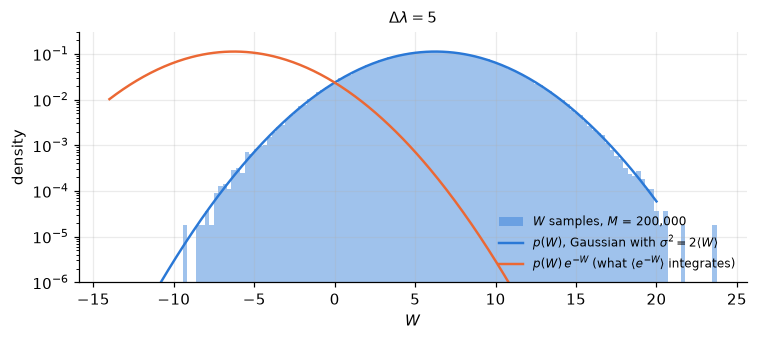

In [4]:
print(' dl    <W>     <e^-W>              sqrt(e^{2<W>}-1)   effective sample size of the weights e^-W')
jar = {}
for d in [0.5, 1, 2, 3, 5]:
    u_d, W_d = trap.open_loop_optimum(N, TF, d)
    w, *_ = trap.run_episodes(trap.open_loop(u_d), M, N, TF, d, rng)
    W = w.sum(1); e = np.exp(-W)
    jar[d] = (W, e.mean(), e.std() / np.sqrt(M))
    ess = e.sum() ** 2 / (e ** 2).sum()
    print(f'{d:4.1f} {W.mean():7.3f}   {e.mean():.4f} ± {e.std() / np.sqrt(M):.4f}      {np.sqrt(np.exp(2 * W_d) - 1):9.2f}'
          f'          {ess:9.0f}')
check('Jarzynski <e^-W> = 1 at dl = 1 (3 sigma)', abs(jar[1][1] - 1) < 3 * jar[1][2],
      f'{jar[1][1]:.4f} ± {jar[1][2]:.4f}')

W5, mu = jar[5][0], W_star_N
ww = np.linspace(-14, 20, 400)
gauss = lambda m: np.exp(-(ww - m) ** 2 / (4 * mu)) / np.sqrt(4 * np.pi * mu)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(W5, bins=120, density=True, color=C_OPEN, alpha=0.45, label=f'$W$ samples, $M$ = {M:,}')
ax.plot(ww, gauss(mu), color=C_OPEN, label=r'$p(W)$, Gaussian with $\sigma^2=2\langle W\rangle$')
ax.plot(ww, gauss(-mu), color=C_FB, label=r'$p(W)\,e^{-W}$ (what $\langle e^{-W}\rangle$ integrates)')
ax.set_yscale('log'); ax.set_ylim(1e-6, 0.3); ax.set_xlabel('$W$'); ax.set_ylabel('density')
ax.set_title(r'$\Delta\lambda=5$', fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

At $\Delta\lambda\le3$ the estimate agrees with 1 to within $3\sigma$. (The CHECK is at $\Delta\lambda=1$; at
$\Delta\lambda=2$ it sits at about $2.7\sigma$.) At $\Delta\lambda=5$ the estimate comes out low, and the quoted
error bar is meaningless, because it is computed from the same undersampled tail. The figure shows why. The
integrand $p(W)e^{-W}$ peaks at $W\approx-6$, more than $3.5\sigma$ below the mean, where the histogram is
almost empty.

The effective sample size of the weights $e^{-W}$ says the same thing in one number: out of 200,000
trajectories, only a handful carry the average. This is why free energies are hard to measure from
far-from-equilibrium pulls.

## 2. The exact open-loop optimum

$\langle W\rangle$ is an exact quadratic in $u=(\lambda_1,\dots,\lambda_N)$. Write the mean path and the protocol as
affine maps of $u$ and you get $\langle W\rangle=\tfrac12u^THu-g^Tu+\text{const}$, so $u^*=H^{-1}g$.

**Continuum.** Write $\lambda=m+\dot m$. Add the jump at $0^+$, which costs $\tfrac12\dot m(0^+)^2$, the ramp,
which costs $\int\dot m(\dot m+\ddot m)\,dt$, and the final jump. The boundary terms cancel, leaving

$$\langle W\rangle=\int_0^{t_f}\dot m^2\,dt+\tfrac12\big(m(t_f)-\Delta\lambda\big)^2 .$$

For a fixed endpoint $m_f$, the integral is smallest at constant speed, which gives
$m_f^2/t_f+\tfrac12(m_f-\Delta\lambda)^2$. Minimizing over $m_f$ gives a speed $c=\Delta\lambda/(t_f+2)$ and
$W^*=c^2(t_f+2)=\Delta\lambda^2/(t_f+2)$. So the trap jumps to $c$ at $0^+$, leads the bead by $c$ throughout, and
jumps from $c(t_f+1)$ to $\Delta\lambda$ at $t_f$. The bead is left lagging, but its relaxation after $t_f$ costs no
work.

CHECK H is positive definite: PASS   eigenvalues from 0.0851 to 0.1998
CHECK u* has constant increments (1e-12): PASS   spread 4.2e-15, increment 0.124948 vs c*dt = 0.125000
   N     W*_N          W*_N - W*     N^2 (W*_N - W*)   u_1      u_N
   5  6.29128150   4.128e-02     1.0320          1.5066   3.4934
  10  6.26039242   1.039e-02     1.0392          1.3769   3.6231
  20  6.25260265   2.603e-03     1.0411          1.3130   3.6870
  40  6.25065095   6.509e-04     1.0415          1.2814   3.7186
  80  6.25016275   1.628e-04     1.0416          1.2657   3.7343
 160  6.25004069   4.069e-05     1.0417          1.2578   3.7422
continuum: W* = 6.25, jumps to c = 1.25, ramp ends at c(tf+1) = 3.75
constant speed: W_lin = 7.0958 (continuum), 7.0973 (N = 20); the optimum saves 11.9%
CHECK W*_N >= W* for every N: PASS   
CHECK W*_N - W* falls as N^-2: PASS   log-log slope -1.9978


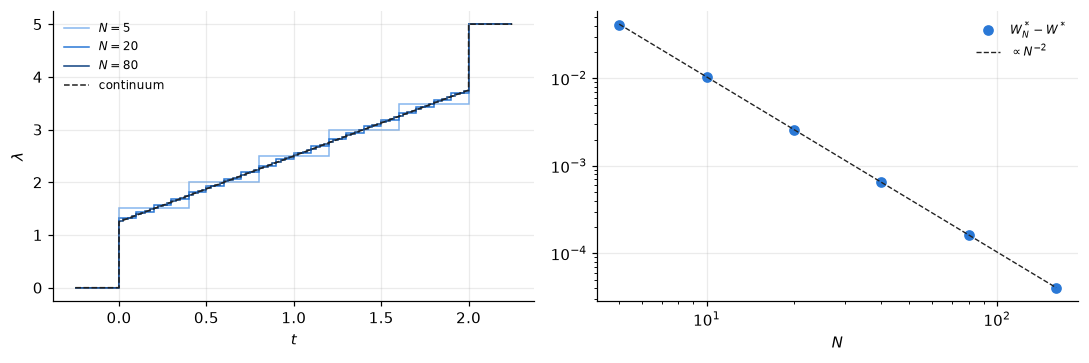

In [5]:
H, g, _ = trap.quadratic_form(N, TF, DL)
ev, V = np.linalg.eigh(H)
check('H is positive definite', ev.min() > 0, f'eigenvalues from {ev.min():.4f} to {ev.max():.4f}')
d = np.diff(u_star)
check('u* has constant increments (1e-12)', np.ptp(d) < 1e-12,
      f'spread {np.ptp(d):.1e}, increment {d[0]:.6f} vs c*dt = {DL / (TF + 2) * DT:.6f}')

Ns = np.array([5, 10, 20, 40, 80, 160])
opt = {n: trap.open_loop_optimum(n, TF, DL) for n in Ns}
excess = np.array([opt[n][1] for n in Ns]) - trap.W_star(TF, DL)
slope = np.polyfit(np.log(Ns), np.log(excess), 1)[0]
print('   N     W*_N          W*_N - W*     N^2 (W*_N - W*)   u_1      u_N')
for n, e in zip(Ns, excess):
    print(f'{n:4d}  {opt[n][1]:.8f}   {e:.3e}     {n * n * e:.4f}          {opt[n][0][0]:.4f}   {opt[n][0][-1]:.4f}')
print(f'continuum: W* = {trap.W_star(TF, DL)}, jumps to c = {DL / (TF + 2)}, ramp ends at c(tf+1) = {DL / (TF + 2) * (TF + 1)}')
print(f'constant speed: W_lin = {trap.W_linear(TF, DL):.4f} (continuum), {W_lin_N:.4f} (N = 20); '
      f'the optimum saves {100 * (1 - trap.W_star(TF, DL) / trap.W_linear(TF, DL)):.1f}%')
check('W*_N >= W* for every N', (excess > 0).all())
check('W*_N - W* falls as N^-2', abs(slope + 2) < 0.01, f'log-log slope {slope:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for n, col in zip([5, 20, 80], ['#86b6ef', '#2a78d6', '#104281']):
    stairs(ax[0], opt[n][0], color=col, label=f'$N={n}$')
ss_curve(ax[0], color=C_INK, ls='--', lw=1, label='continuum')
ax[0].set_xlabel('$t$'); ax[0].set_ylabel(r'$\lambda$'); ax[0].legend(fontsize=8)
ax[1].loglog(Ns, excess, 'o', color=C_OPEN, ms=6, label=r'$W^*_N-W^*$')
ax[1].loglog(Ns, excess[2] * (Ns / 20.0) ** -2, color=C_INK, lw=0.9, ls='--', label=r'$\propto N^{-2}$')
ax[1].set_xlabel('$N$'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The discrete optimum is *exactly* a ramp plus two jumps, with constant increments to machine precision. It
converges to Schmiedl–Seifert with an excess of $\approx1.04/N^2$. Its first and last held values sit half a ramp
step inside the continuum jumps (1.25 and 3.75), because each held value is effectively the ramp at the interval
midpoint. Every eigenvalue of the Hessian lies between 0.085 and 0.20. The work landscape is shallow in *every*
direction: moving each $\lambda_k$ by 0.1 costs only about $10^{-3}\,k_BT$ per step. That matters in step 3.

## 3. REINFORCE rediscovers the jumps (open loop)

The policy is $\lambda_k\sim\mathcal N(\theta_k,\sigma^2)$ with $\sigma=0.3$, and the agent sees only per-step
rewards from single trajectories. Action $k$ can only affect $w_k,\dots,w_N$, so its score is weighted by the
**reward-to-go**:

$$\hat g_k=\Big\langle (G_k-b_k)\,\frac{\lambda_k-\theta_k}{\sigma^2}\Big\rangle,\qquad G_k=-\sum_{j\ge k}w_j,$$

where $b_k$ is the batch mean of $G_k$.

**Prediction.** Smoothing a quadratic with Gaussian noise only adds a constant,
$\mathbb E_\lambda\langle W\rangle(\lambda)=\langle W\rangle(\theta)+\tfrac{\sigma^2}{2}\mathrm{tr}H$. So the
expected gradient is exactly $-(H\theta-g)$, and the fixed point of REINFORCE is $u^*$ itself, not a smoothed
version of it.

In [6]:
theta = u_lin
rng = np.random.default_rng(11)
B, REPS = 20_000, 20
terms_rtg = np.concatenate([agents.grad_open(theta, 0.3, B, N, TF, DL, rng)[1] for _ in range(REPS)])
terms_full = np.concatenate([agents.grad_open(theta, 0.3, B, N, TF, DL, rng, to_go=False)[1] for _ in range(REPS)])
exact_grad = -(H @ theta - g)
chi2_999 = np.quantile(np.random.default_rng(0).chisquare(N, 2_000_000), 0.999)
for name, T in [('reward-to-go', terms_rtg), ('full return', terms_full)]:
    z = (T.mean(0) - exact_grad) / (T.std(0) / np.sqrt(len(T)))
    check(f'REINFORCE gradient ({name}) is unbiased: chi2 < 99.9% point', np.sum(z ** 2) < chi2_999,
          f'chi2/dof = {np.mean(z ** 2):.2f}, per-episode variance {T.var(0).mean():.1f}')

gap = W_lin_N - W_star_N
print(f'\ngap from constant speed to optimum: {gap:.4f}')
print('seed   last-iterate excess   Polyak excess   theta_1 (exact %.3f)   theta_N (exact %.3f)' % (u_star[0], u_star[-1]))
for s, r in zip(OPEN_SEEDS, open_runs):
    ex_last, ex_avg = trap.mean_work(r[0], N, TF, DL) - W_star_N, trap.mean_work(r[1], N, TF, DL) - W_star_N
    print(f'{s:3d}        {ex_last:.4f}              {ex_avg:.5f}         {r[1][0]:.3f}                  {r[1][-1]:.3f}')
    check(f'open-loop RL seed {s}: Polyak excess < 1% of gap', ex_avg < 0.01 * gap, f'{ex_avg / gap:.2%} of gap')
    check(f'open-loop RL seed {s}: both jumps found (0.15)',
          abs(r[1][0] - u_star[0]) < 0.15 and abs(r[1][-1] - u_star[-1]) < 0.15)

CHECK REINFORCE gradient (reward-to-go) is unbiased: chi2 < 99.9% point: PASS   chi2/dof = 0.49, per-episode variance 73.8
CHECK REINFORCE gradient (full return) is unbiased: chi2 < 99.9% point: PASS   chi2/dof = 0.55, per-episode variance 162.0

gap from constant speed to optimum: 0.8446
seed   last-iterate excess   Polyak excess   theta_1 (exact 1.313)   theta_N (exact 3.687)
  0        0.0164              0.00270         1.408                  3.741
CHECK open-loop RL seed 0: Polyak excess < 1% of gap: PASS   0.32% of gap
CHECK open-loop RL seed 0: both jumps found (0.15): PASS   
  1        0.0280              0.00242         1.262                  3.676
CHECK open-loop RL seed 1: Polyak excess < 1% of gap: PASS   0.29% of gap
CHECK open-loop RL seed 1: both jumps found (0.15): PASS   
  2        0.0208              0.00217         1.300                  3.717
CHECK open-loop RL seed 2: Polyak excess < 1% of gap: PASS   0.26% of gap
CHECK open-loop RL seed 2: both jumps found (0.15

Reward-to-go and the full return are both unbiased, but reward-to-go has less than half the per-episode
variance. The full return adds the noise of every earlier jump to every score, and none of that noise carries
information about the later actions.

Every seed recovers more than 99.5% of the available saving, and every seed finds both jumps. Yet the
learned protocols still differ visibly from $u^*$. To see why, decompose $\theta-u^*=\sum_ip_iv_i$ along the
eigenvectors of $H$. The excess work is $\tfrac12\sum_ih_ip_i^2$, and the restoring gradient along mode $i$ is
$h_ip_i$. Compare that restoring force with the noise in a batch gradient.

seed-averaged theta - u*: 5 of 20 components beyond 2 standard errors; largest offset 0.043
Hessian eigenvalues 0.085 .. 0.200 (condition number 2.3)
rms |theta - u*| per component: 0.040  ->  restoring gradient ~ 0.0077 per component
batch-gradient noise per component (B = 1000): 0.272
largest residual projection: mode with h = 0.085


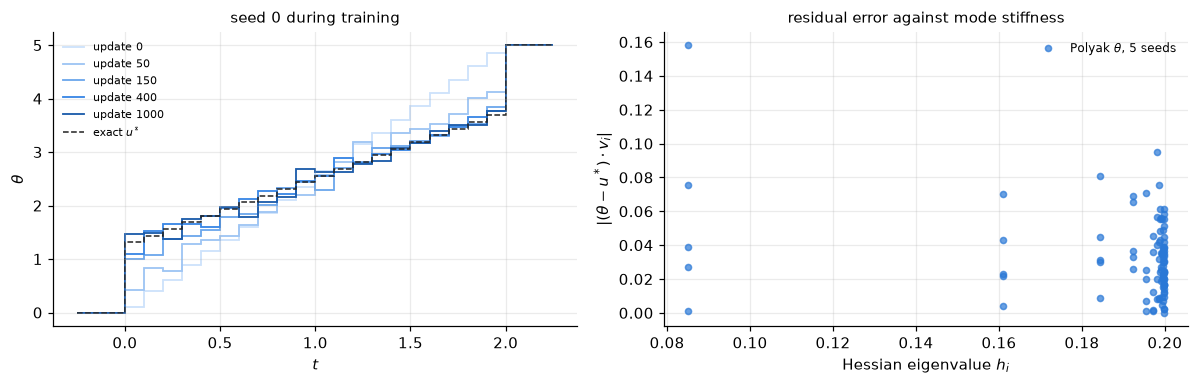

In [7]:
P_avg = np.array([V.T @ (r[1] - u_star) for r in open_runs])      # (seeds, modes)
th_avg = np.array([r[1] for r in open_runs])
off, se = th_avg.mean(0) - u_star, th_avg.std(0, ddof=1) / np.sqrt(len(open_runs))
print(f'seed-averaged theta - u*: {np.sum(np.abs(off) > 2 * se)} of {N} components beyond 2 standard errors; '
      f'largest offset {np.abs(off).max():.3f}')
grad_noise = np.sqrt(terms_rtg.var(0).mean() / 1000)
print(f'Hessian eigenvalues {ev.min():.3f} .. {ev.max():.3f} (condition number {ev.max() / ev.min():.1f})')
print(f'rms |theta - u*| per component: {np.sqrt(np.mean((th_avg - u_star) ** 2)):.3f}  ->  restoring gradient ~ '
      f'{ev.mean() * np.sqrt(np.mean((th_avg - u_star) ** 2)):.4f} per component')
print(f'batch-gradient noise per component (B = 1000): {grad_noise:.3f}')
print(f'largest residual projection: mode with h = {ev[np.argmax(np.abs(P_avg).mean(0))]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
snaps = open_runs[0][3]
shades = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab']
for (it, th), col in zip(sorted(snaps.items()), shades):
    stairs(ax[0], th, color=col, lw=1.2, label=f'update {it}')
stairs(ax[0], u_star, color=C_INK, lw=1.0, ls='--', label='exact $u^*$')
ax[0].set_xlabel('$t$'); ax[0].set_ylabel(r'$\theta$'); ax[0].legend(fontsize=7); ax[0].set_title('seed 0 during training', fontsize=10)
for i in range(len(open_runs)):
    ax[1].plot(ev, np.abs(P_avg[i]), 'o', color=C_OPEN, ms=4, alpha=0.7, label='Polyak $\\theta$, 5 seeds' if i == 0 else None)
ax[1].set_xlabel('Hessian eigenvalue $h_i$'); ax[1].set_ylabel(r'$|(\theta-u^*)\cdot v_i|$'); ax[1].legend(fontsize=8)
ax[1].set_title('residual error against mode stiffness', fontsize=10)
plt.tight_layout(); plt.show()

The jumps emerge over the first few hundred updates. After that the protocol never settles exactly. The
reason is not one flat direction, since the condition number is only about 2.3. The whole landscape is shallow.
A residual of a few hundredths per component pulls back with a gradient of order $10^{-2}$, while each batch
gradient carries noise of order $0.3$. Adam and Polyak averaging beat that noise down, but slowly. The softest
mode does hold the largest residual, as expected.

The seed-averaged protocol sits a few hundredths off $u^*$ in some components, beyond the seed-to-seed error,
while its *work* is within 0.3% of the gap. RL finds near-optimal work long before it pins down the optimal
protocol. Judge it on the cost, and read the parameters only to within the shallowness of the landscape.

## 4. Feedback: exact Bellman, then policy gradient

Now the agent measures $x_{k-1}$ before choosing $\lambda_k$. Augment the state to $z=(x,\lambda_{\rm prev},1)$.
The dynamics is linear, the noise is Gaussian, and the cost is quadratic, so the value function is exactly
quadratic, $V_k(z)=\tfrac12z^TP_kz+c_k$.

The recursion starts from the forced final jump,
$V_N=\tfrac12(x-\Delta\lambda)^2-\tfrac12(x-\lambda_{\rm prev})^2$, and steps back with

$$V_{k-1}(z)=\min_u\Big[\tfrac12(x-u)^2-\tfrac12(x-\lambda_{\rm prev})^2+\mathbb E\,V_k(z')\Big].$$

Each step is one Schur complement. The minimizer is linear, $u^*=g_kx+b_k\lambda_{\rm prev}+h_k$. The state cost
$-\tfrac12(x-\lambda_{\rm prev})^2$ is *concave*, so the minimum exists only if the coefficient $K_{uu}$ of $u^2$
stays positive.

**Exact policy evaluation.** Under any linear policy, $(x,\lambda_{\rm prev})$ stays jointly Gaussian.
Propagating its mean and covariance gives the exact expected work of that policy. This is RL's "policy
evaluation" done without sampling, and it provides every learning curve in this notebook.

In [8]:
check('K_uu > 0 at every step (the minimum exists)', Kuu.min() > 0, f'min K_uu = {Kuu.min():.3f}')
check('moment propagation reproduces the Bellman value (1e-10)',
      abs(trap.eval_linear_policy(G_fb, N, TF, DL) - W_fb) < 1e-10, f'W_fb = {W_fb:.6f}')
check('gain on lam_prev is exactly 0 (1e-12)', np.abs(G_fb[:, 1]).max() < 1e-12, f'max |b_k| = {np.abs(G_fb[:, 1]).max():.1e}')
check('last step: lam_N = (x + dl)/2', abs(G_fb[-1, 0] - 0.5) < 1e-12 and abs(G_fb[-1, 2] - DL / 2) < 1e-12)
m, lam, path = 0.0, 0.0, []
for k in range(N):
    lam = G_fb[k] @ [m, lam, 1.0]; path.append(lam); m = A_OU * m + (1 - A_OU) * lam
check('certainty equivalence: feedback law on the mean path = u* (1e-12)',
      np.abs(np.array(path) - u_star).max() < 1e-12, f'{np.abs(np.array(path) - u_star).max():.1e}')
w, *_ = trap.run_episodes(trap.feedback_policy(G_fb), M, N, TF, DL, np.random.default_rng(5))
Wfb_samples = w.sum(1); err = Wfb_samples.std() / np.sqrt(M)
check('simulated feedback policy matches Bellman (3 sigma)', abs(Wfb_samples.mean() - W_fb) < 3 * err,
      f'{Wfb_samples.mean():.4f} ± {err:.4f} vs {W_fb:.4f}')
print(f'gains g_k: {G_fb[0, 0]:.4f} -> {G_fb[-1, 0]:.4f};  P(W < 0) = {np.mean(Wfb_samples < 0):.3f}')

print('\nvalue of information:')
print('   N    W*_N      W_fb      W*_N - W_fb')
for n in [10, 20, 40, 80, 160, 320]:
    wo, wf = trap.open_loop_optimum(n, TF, DL)[1], trap.bellman(n, TF, DL)[1]
    print(f'{n:4d}  {wo:.4f}   {wf:.4f}    {wo - wf:.4f}')

CHECK K_uu > 0 at every step (the minimum exists): PASS   min K_uu = 0.186
CHECK moment propagation reproduces the Bellman value (1e-10): PASS   W_fb = 5.469701
CHECK gain on lam_prev is exactly 0 (1e-12): PASS   max |b_k| = 0.0e+00
CHECK last step: lam_N = (x + dl)/2: PASS   
CHECK certainty equivalence: feedback law on the mean path = u* (1e-12): PASS   1.3e-14


CHECK simulated feedback policy matches Bellman (3 sigma): PASS   5.4777 ± 0.0083 vs 5.4697
gains g_k: 0.7374 -> 0.5000;  P(W < 0) = 0.045

value of information:
   N    W*_N      W_fb      W*_N - W_fb
  10  6.2604   5.5482    0.7122
  20  6.2526   5.4697    0.7829
  40  6.2507   5.4287    0.8219
  80  6.2502   5.4077    0.8425
 160  6.2500   5.3970    0.8530
 320  6.2500   5.3917    0.8583


**Why $b_k=0$.** $\lambda_{\rm prev}$ enters the problem only through $-\tfrac12(x-\lambda_{\rm prev})^2$. That term is
the energy the trap released when the bead moved, and no action can change it. The transition does not
involve $\lambda_{\rm prev}$ at all. So $V_k(x,\lambda_{\rm prev})=\tilde V_k(x)-\tfrac12(x-\lambda_{\rm prev})^2$: the
value depends on $\lambda_{\rm prev}$, but the decision does not.

**Certainty equivalence.** The feedback law applied along the mean path *is* $u^*$. That is why the three
feedback runs in the headline scatter around $u^*$. The feedback agent does what the open-loop agent would have
done, and then corrects for the bead's thermal kick. Each correction is worth work, and measuring more often
($N\uparrow$) is worth more.

**Policy gradient with feedback.** The policy is linear Gaussian with mean $g_kx+b_k\lambda_{\rm prev}+h_k$, the
estimator is the same reward-to-go REINFORCE, and training starts from the open-loop optimum
($g=b=0$, $h=u^*$).

seed   Polyak W    fraction of feedback gain   max|g - g*|   max|b|
 10    5.4796           0.987               0.102       0.195
CHECK feedback RL seed 10: >= 95% of the exact feedback gain: PASS   98.7%
 11    5.4801           0.987               0.097       0.221
CHECK feedback RL seed 11: >= 95% of the exact feedback gain: PASS   98.7%
 12    5.4793           0.988               0.181       0.212
CHECK feedback RL seed 12: >= 95% of the exact feedback gain: PASS   98.8%
 13    5.4794           0.988               0.177       0.219
CHECK feedback RL seed 13: >= 95% of the exact feedback gain: PASS   98.8%


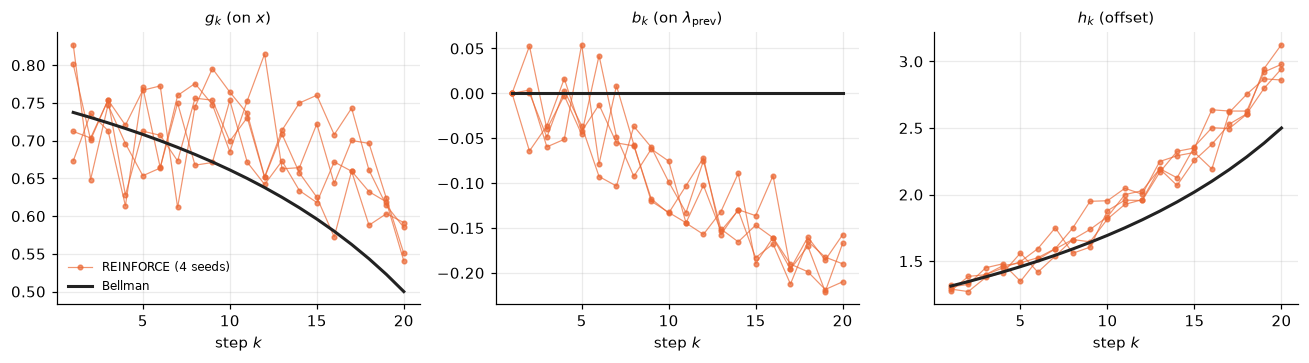

In [9]:
fb_gain = W_star_N - W_fb
print('seed   Polyak W    fraction of feedback gain   max|g - g*|   max|b|')
for s, r in zip(FB_SEEDS, fb_runs):
    Wr = trap.eval_linear_policy(r[1], N, TF, DL); frac = (W_star_N - Wr) / fb_gain
    print(f'{s:3d}    {Wr:.4f}           {frac:.3f}               {np.abs(r[1][:, 0] - G_fb[:, 0]).max():.3f}       {np.abs(r[1][:, 1]).max():.3f}')
    check(f'feedback RL seed {s}: >= 95% of the exact feedback gain', frac >= 0.95, f'{frac:.1%}')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
k = np.arange(1, N + 1)
for j, (name, lab) in enumerate([('g', r'$g_k$ (on $x$)'), ('b', r'$b_k$ (on $\lambda_{\rm prev}$)'), ('h', r'$h_k$ (offset)')]):
    for i, r in enumerate(fb_runs):
        ax[j].plot(k, r[1][:, j], 'o-', color=C_FB, ms=3, lw=0.8, alpha=0.7, label='REINFORCE (4 seeds)' if i == 0 else None)
    ax[j].plot(k, G_fb[:, j], color=C_INK, lw=2, label='Bellman')
    ax[j].set_xlabel('step $k$'); ax[j].set_title(lab, fontsize=10)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Every seed captures about 99% of the feedback gain, and the gains $g_k$ scatter around the exact profile. But
$b_k$ drifts to about $-0.2$ at late steps in every seed, where the exact value is 0. The brief offered a
hypothesis: early on, when $g\approx0$, $\lambda_{\rm prev}$ stands in for $x$. That would predict $b>0$, not
$b<0$, so it already looks wrong.

Here is a cleaner test. Start one run *at the exact optimum*. If $b=0$ is the fixed point, $b$ should stay
there. Then look at where the drifting runs went: if $b$ moved along a ridge with $h$, the shift in $h_k$ should
equal $-b_k\bar\lambda_{k-1}$, where $\bar\lambda_{k-1}=u^*_{k-1}$ is the mean of $\lambda_{\rm prev}$.

CHECK started at the exact optimum, b stays near 0 (max |b| < 0.1): PASS   max |b| = 0.094, W = 5.4776
CHECK drifted runs moved along the ridge dh = -b * mean(lam_prev) (corr > 0.9): PASS   corr = 0.928


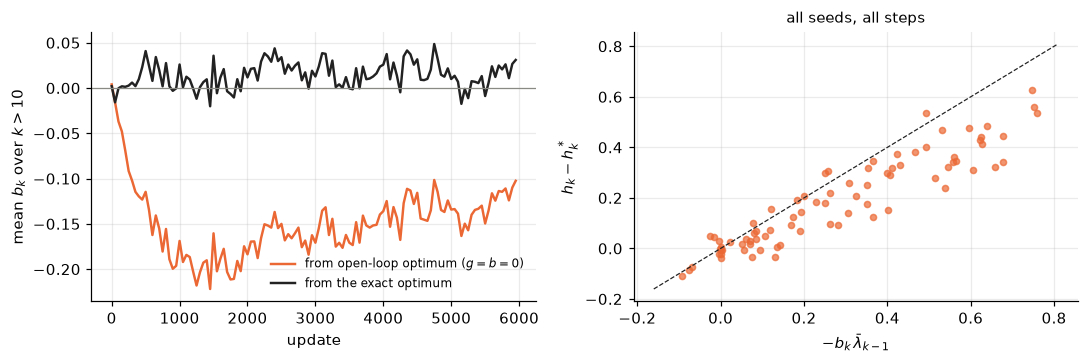

In [10]:
_, G_from_exact, _, hist_exact = agents.reinforce_feedback(G_fb, N, TF, DL, seed=FB_SEEDS[0])
hist_open = fb_runs[0][3]
lam_bar = np.concatenate([[0.0], u_star[:-1]])            # mean of lam_prev before each action
db = np.concatenate([r[1][:, 1] for r in fb_runs]); dh = np.concatenate([r[1][:, 2] - G_fb[:, 2] for r in fb_runs])
ridge = -db * np.tile(lam_bar, len(fb_runs))
corr = np.corrcoef(ridge, dh)[0, 1]
check('started at the exact optimum, b stays near 0 (max |b| < 0.1)', np.abs(G_from_exact[:, 1]).max() < 0.1,
      f'max |b| = {np.abs(G_from_exact[:, 1]).max():.3f}, W = {trap.eval_linear_policy(G_from_exact, N, TF, DL):.4f}')
check('drifted runs moved along the ridge dh = -b * mean(lam_prev) (corr > 0.9)', corr > 0.9, f'corr = {corr:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
it = fb_runs[0][2][:, 0]
ax[0].plot(it, hist_open[:, 10:, 1].mean(1), color=C_FB, label=r'from open-loop optimum ($g=b=0$)')
ax[0].plot(it, hist_exact[:, 10:, 1].mean(1), color=C_INK, label='from the exact optimum')
ax[0].axhline(0, color=C_LIN, lw=0.8); ax[0].set_xlabel('update'); ax[0].set_ylabel(r'mean $b_k$ over $k>10$'); ax[0].legend(fontsize=8)
ax[1].plot(ridge, dh, 'o', color=C_FB, ms=4, alpha=0.7)
lim = [min(ridge.min(), dh.min()) - 0.05, max(ridge.max(), dh.max()) + 0.05]
ax[1].plot(lim, lim, color=C_INK, lw=0.8, ls='--')
ax[1].set_xlabel(r'$-b_k\,\bar\lambda_{k-1}$'); ax[1].set_ylabel(r'$h_k-h_k^*$'); ax[1].set_title('all seeds, all steps', fontsize=10)
plt.tight_layout(); plt.show()

The hypothesis fails, and the test points to a different cause. Started at the optimum, $b$ stays at 0, so
nothing biases the fixed point. In the runs that drifted, $h$ moved roughly by $-b\,\bar\lambda_{\rm prev}$ (correlation 0.93, with a
slope a little under 1 because $g$ also shifted). Along trajectories, $\lambda_{\rm prev}$ fluctuates by less than 1
about a mean of up to 3.7. So the features $\lambda_{\rm prev}$ and $1$ are nearly collinear, and the work constrains only the
combination $b\bar\lambda+h$.

$b$ was knocked onto this flat ridge during the fast phase, while $g$ was being learned, and it relaxes back
slowly. This is the same lesson as the soft modes in step 3, with the standard fix: centre the features. The
Bellman solution tells you which state variables matter. A policy-gradient agent with poorly conditioned
features does not.

## 5. Value-based RL: fitted Q-iteration on the state–action space

Policy gradient never builds a value function. The other family of RL methods learns $Q_k(s,a)$ on the
state–action space and acts greedily. Here $Q_k(x,\lambda_{\rm prev},u)$ is exactly quadratic. Fit it backward in
$k$ by least squares on the 10 monomials of degree $\le2$. The target is $w+V_{k+1}(x',u)$, where $V_{k+1}$ is the
minimum over $u'$ of the fitted $Q_{k+1}$. States and actions are drawn uniformly from a box that covers the
optimal path, with one OU step per sample. The greedy policy solves $\partial_uQ_k=0$, which is linear in the
state.

samples/step    W          max|g-g*|   max|b|    max|h-h*|   time
    10000      5.4751     0.040       0.036     0.118       0.04 s


   100000      5.4709     0.022       0.007     0.078       0.35 s
  Bellman       5.4697
CHECK FQI (1e5 samples/step) is within 0.01 of the Bellman work: PASS   
CHECK FQI finds b = 0 (max |b| < 0.05): PASS   

transitions used: FQI 2.0e+06   vs   feedback REINFORCE 1.2e+08 per seed


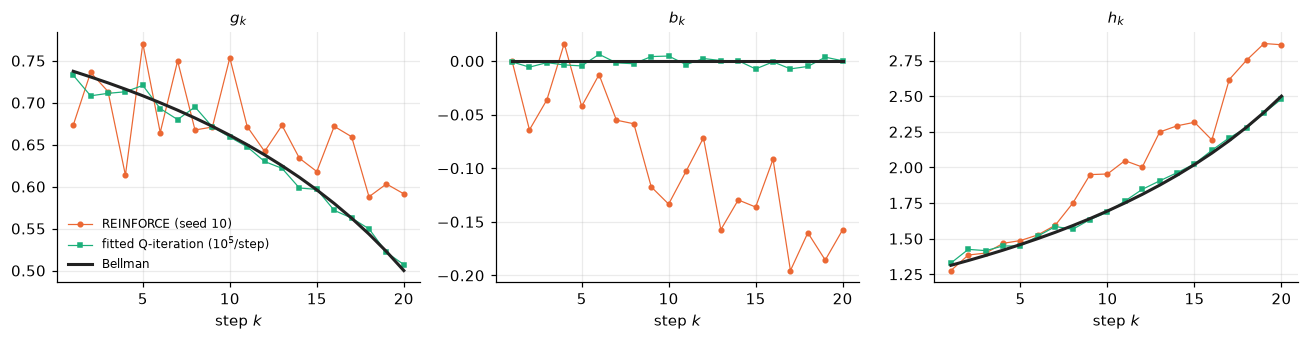

In [11]:
print('samples/step    W          max|g-g*|   max|b|    max|h-h*|   time')
fqi = {}
for Ms in [10_000, 100_000]:
    t0 = time.time(); Gq = agents.fitted_q(N, TF, DL, Ms, seed=0); dt_ = time.time() - t0
    fqi[Ms] = Gq; Wq = trap.eval_linear_policy(Gq, N, TF, DL)
    print(f'{Ms:9d}      {Wq:.4f}     {np.abs(Gq[:, 0] - G_fb[:, 0]).max():.3f}       {np.abs(Gq[:, 1]).max():.3f}     '
          f'{np.abs(Gq[:, 2] - G_fb[:, 2]).max():.3f}       {dt_:.2f} s')
print(f'  Bellman       {W_fb:.4f}')
Gq = fqi[100_000]
check('FQI (1e5 samples/step) is within 0.01 of the Bellman work', trap.eval_linear_policy(Gq, N, TF, DL) - W_fb < 0.01)
check('FQI finds b = 0 (max |b| < 0.05)', np.abs(Gq[:, 1]).max() < 0.05)
print(f'\ntransitions used: FQI {N * 100_000:.1e}   vs   feedback REINFORCE {6000 * 1000 * N:.1e} per seed')

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for j, lab in enumerate([r'$g_k$', r'$b_k$', r'$h_k$']):
    ax[j].plot(k, fb_runs[0][1][:, j], 'o-', color=C_FB, ms=3, lw=0.8, label='REINFORCE (seed 10)')
    ax[j].plot(k, Gq[:, j], 's-', color=C_FQI, ms=3, lw=0.8, label='fitted Q-iteration ($10^5$/step)')
    ax[j].plot(k, G_fb[:, j], color=C_INK, lw=2, label='Bellman')
    ax[j].set_xlabel('step $k$'); ax[j].set_title(lab, fontsize=10)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Fitted Q-iteration recovers the exact policy from 60 times fewer transitions, in a fraction of a second, and it
gets $b\approx0$ right where policy gradient did not. That is not a fair race, though. Its function class
(quadratics in $x,\lambda_{\rm prev},u$) contains the exact $Q$, which is knowledge the policy-gradient agent was never
given.

In a non-linear environment the advantage would shrink. With an anharmonic trap, or a stiffness protocol whose
work is not quadratic, the true $Q$ leaves the quadratic class. Fitted Q-iteration then inherits a systematic
approximation error at every backward step, compounded through $k$. Policy gradient still climbs the true
objective, slowly.

## Push harder

**An information engine.** Prediction, written before running: as $t_f$ grows the bead has time to
re-equilibrate between measurements. A measurement followed by a jump of the trap onto the bead then extracts
$\tfrac12\langle(x-\lambda)^2\rangle=\tfrac12k_BT$. With $N=20$ fixed, $W_{\rm fb}$ should go negative and head
toward $-N/2=-10$ as $t_f\to\infty$, while the drag itself costs $W^*\to0$.

W_fb crosses zero at tf = 6.5393
tf      W*       W_lin     W_fb
  0.5   10.000   10.653     9.850
    1    8.333    9.197     7.995
    2    6.250    7.096     5.470
    4    4.167    4.716     2.416
    8    2.500    2.735    -1.035
  100    0.245    0.247    -8.060
  400    0.062    0.062    -8.082
prediction -N/2 = -10.0: MISSED, W_fb(tf = 400) = -8.0821
CHECK W_fb(tf -> inf) equals the fully relaxed closed form (1e-6): PASS   closed form -8.082083


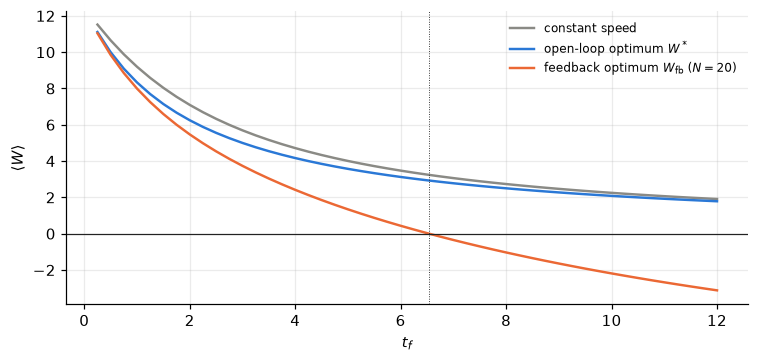

In [12]:
tfs = np.concatenate([np.linspace(0.25, 12, 48), [20, 50, 100, 400]])
Wfb_t = np.array([trap.bellman(N, t, DL)[1] for t in tfs])
lo, hi = 0.25, 12.0
for _ in range(60):                                       # bisection for W_fb(tf) = 0
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if trap.bellman(N, mid, DL)[1] > 0 else (lo, mid)
tf0 = 0.5 * (lo + hi)
print(f'W_fb crosses zero at tf = {tf0:.4f}')
print('tf      W*       W_lin     W_fb')
for t in [0.5, 1, 2, 4, 8, 100, 400]:
    print(f'{t:5g}  {trap.W_star(t, DL):7.3f}  {trap.W_linear(t, DL):7.3f}  {trap.bellman(N, t, DL)[1]:8.3f}')
print(f'prediction -N/2 = {-N / 2}: MISSED, W_fb(tf = 400) = {trap.bellman(N, 400, DL)[1]:.4f}')
W_relaxed = -(N + 1) / 2 + (DL ** 2 + 1) / (2 * (N + 1)) + 0.5 * np.sum(1.0 / np.arange(1, N + 1))
check('W_fb(tf -> inf) equals the fully relaxed closed form (1e-6)', abs(trap.bellman(N, 400, DL)[1] - W_relaxed) < 1e-6,
      f'closed form {W_relaxed:.6f}')
fig, ax = plt.subplots(figsize=(7, 3.4))
tt = tfs[tfs <= 12]
ax.plot(tt, [trap.W_linear(t, DL) for t in tt], color=C_LIN, label='constant speed')
ax.plot(tt, [trap.W_star(t, DL) for t in tt], color=C_OPEN, label=r'open-loop optimum $W^*$')
ax.plot(tt, Wfb_t[tfs <= 12], color=C_FB, label=r'feedback optimum $W_{\rm fb}$ ($N=20$)')
ax.axhline(0, color=C_INK, lw=0.8); ax.axvline(tf0, color=C_INK, lw=0.6, ls=':')
ax.set_xlabel('$t_f$'); ax.set_ylabel(r'$\langle W\rangle$'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The sign change held: past $t_f\approx6.54$ the feedback agent does net *negative* work. It turns heat from the
bath into work using its measurements, and the trap still ends up at $\Delta\lambda$. But the asymptote **missed**:
$W_{\rm fb}\to-8.08$, not $-10$.

The prediction forgot that a trap which keeps jumping onto the bead inherits the bead's random walk, and the
trap must still end at $\Delta\lambda$. Here is the fully relaxed problem ($a\to0$) solved by hand. There are
$N+1$ relaxation events (the $N$ measurements plus the final jump), each releasing $\tfrac12$. Write
$J_k(x)=\tfrac12p_k(x-\Delta\lambda)^2+c_k$ and minimize $\tfrac12(x-u)^2+\mathbb E J_k(u+\xi)$. This gives
$u=(x+p_k\Delta\lambda)/(1+p_k)$ and $p_{k-1}=p_k/(1+p_k)$, so $p_k=1/(N-k+1)$. Altogether

$$W_{\rm fb}(t_f\to\infty)=-\frac{N+1}{2}+\frac{\Delta\lambda^2+1}{2(N+1)}+\frac12H_N ,$$

with $H_N$ the harmonic number. The three terms are the energy released, a quasi-static drag in $N+1$ steps, and
the cost of fighting the bead's diffusion. At $N=20$ this is $-10.5+0.62+1.80=-8.082$, matching the Bellman
recursion. The gains also follow: $g_k\to(N-k+1)/(N-k+2)$, which starts at $20/21$ and ends at $\tfrac12$.

**The continuum limit of feedback.** Prediction: $W^*_N$ converges as $N^{-2}$ because a held value is a midpoint
rule for a smooth ramp. A feedback correction, by contrast, acts on a measurement up to $\Delta t$ old, so
$W_{\rm fb}(N)$ should converge only as $N^{-1}$.

In [13]:
Ns_fb = np.array([20, 40, 80, 160, 320, 640, 1280])
Wfb_N = np.array([trap.bellman(n, TF, DL)[1] for n in Ns_fb])
d1 = np.diff(Wfb_N)
print('successive differences:', np.round(d1, 5), '  ratios:', np.round(d1[:-1] / d1[1:], 3))
W_inf = Wfb_N[-1] + d1[-1]                                 # Richardson for a 1/N error: W(2N) + (W(2N) - W(N))
print(f'W_fb(N -> inf) ~ {W_inf:.4f}, which is {trap.W_star(TF, DL) - W_inf:.4f} below the open-loop continuum optimum {trap.W_star(TF, DL)}')
check('W_fb(N) converges as 1/N (difference ratio -> 2 within 2%)', abs(d1[-2] / d1[-1] - 2) < 0.04, f'{d1[-2] / d1[-1]:.3f}')

successive differences: [-0.041   -0.02102 -0.01065 -0.00536 -0.00269 -0.00135]   ratios: [1.951 1.974 1.986 1.993 1.997]
W_fb(N -> inf) ~ 5.3863, which is 0.8637 below the open-loop continuum optimum 6.25
CHECK W_fb(N) converges as 1/N (difference ratio -> 2 within 2%): PASS   1.997


Held. The successive differences halve with each doubling of $N$, so the error is first order. The extrapolated
continuous-measurement limit is about 5.386, roughly $0.86\,k_BT$ below the open-loop continuum optimum of 6.25.

**A noisy measurement (a POMDP).** Measure $y=x+\eta$ with $\eta\sim\mathcal N(0,s^2)$. Now the state is not
observed. Prediction, from the separation principle: the optimal policy is a Kalman filter for $\hat x$ fed into
*the same* Bellman gains. Its work should rise monotonically from $W_{\rm fb}$ at $s=0$ to $W^*_N$ as $s\to\infty$,
where the filter ignores the data and the policy falls back to the open-loop optimum.

In [14]:
def kalman_policy(G, s, M):
    st = {}
    def policy(k, y, lam):
        if k == 0:
            xp, Pp = np.zeros(M), 1.0                          # equilibrium prior
        else:
            xp, Pp = A_OU * st['x'] + (1 - A_OU) * lam, A_OU ** 2 * st['P'] + 1 - A_OU ** 2
        K = Pp / (Pp + s * s)
        st['x'], st['P'] = xp + K * (y - xp), (1 - K) * Pp
        return G[k, 0] * st['x'] + G[k, 1] * lam + G[k, 2]
    return policy

Mk = 200_000; rows = []
for s in [0.0, 0.25, 0.5, 1.0, 2.0, 100.0]:
    w, *_ = trap.run_episodes(kalman_policy(G_fb, s, Mk), Mk, N, TF, DL, np.random.default_rng(int(10 * s) + 1), obs_noise=s)
    W = w.sum(1); rows.append((s, W.mean(), W.std() / np.sqrt(Mk)))
    print(f's = {s:6.2f}   <W> = {W.mean():.4f} ± {W.std() / np.sqrt(Mk):.4f}')
check('Kalman policy at s = 0 reproduces W_fb (3 sigma)', abs(rows[0][1] - W_fb) < 3 * rows[0][2])
check('Kalman policy at s = 100 falls back to W*_N (3 sigma)', abs(rows[-1][1] - W_star_N) < 3 * rows[-1][2])
check('work rises monotonically with measurement noise', np.all(np.diff([r[1] for r in rows]) > 0))

_, G_y, _, _ = agents.reinforce_feedback(G0, N, TF, DL, seed=21, obs_noise=1.0)
w, *_ = trap.run_episodes(trap.feedback_policy(G_y), Mk, N, TF, DL, np.random.default_rng(3), obs_noise=1.0)
print(f'\ns = 1: REINFORCE linear in (y, lam_prev): <W> = {w.sum(1).mean():.4f} ± {w.sum(1).std() / np.sqrt(Mk):.4f}'
      f'   vs Kalman + Bellman gains {rows[3][1]:.4f} ± {rows[3][2]:.4f}')

s =   0.00   <W> = 5.4646 ± 0.0082


s =   0.25   <W> = 5.5080 ± 0.0082


s =   0.50   <W> = 5.5853 ± 0.0082
s =   1.00   <W> = 5.7313 ± 0.0082


s =   2.00   <W> = 5.9265 ± 0.0081


s = 100.00   <W> = 6.2416 ± 0.0079
CHECK Kalman policy at s = 0 reproduces W_fb (3 sigma): PASS   
CHECK Kalman policy at s = 100 falls back to W*_N (3 sigma): PASS   
CHECK work rises monotonically with measurement noise: PASS   



s = 1: REINFORCE linear in (y, lam_prev): <W> = 5.8217 ± 0.0081   vs Kalman + Bellman gains 5.7313 ± 0.0082


The separation principle holds. At $s=1$ the Kalman policy reaches 5.731. A REINFORCE policy that is linear in
the raw $(y,\lambda_{\rm prev})$ reaches 5.822, which is 83% of the Kalman policy's saving over open loop. Its input $\lambda_{\rm prev}$ is itself a function of the earlier measurements,
so the policy carries some memory for free. The right state for a POMDP is the *belief*, here
$(\hat x,P)$, and $\lambda_{\rm prev}$ is a partial stand-in for it.

**Tabular Q-learning: the textbook picture, at a cost you can measure.** Make both spaces finite. The measured
$x$ lives on a grid of spacing $\delta x$, and the action $u$ on a grid of spacing $\delta u$. To make the state
Markov without $\lambda_{\rm prev}$, regroup the work so that each reward depends only on $(x,u,x')$:

$$W=-\tfrac12x_0^2+\sum_{k=1}^{N}\Big[\tfrac12(x_{k-1}-\lambda_k)^2-\tfrac12(x_k-\lambda_k)^2\Big]+\tfrac12(x_N-\Delta\lambda)^2 .$$

The sum telescopes back to $\sum_kw_k$. This is the same fact as $b_k=0$, seen from the reward side.

For an exact $Q^*$ the environment must *be* the discrete MDP. After every OU step, $x$ is snapped to the nearest
grid point, and the transition probabilities $P(x'|x,u)$ are exact Gaussian bin masses. Value iteration on that
MDP gives $Q^*$, and Q-learning that samples the same MDP must converge to it. The cost of discretizing is then
measured separately, by running the tabular policy in the real, continuous environment. To keep the error bar
small, it is compared *paired*, on the same random numbers, with the exact feedback policy.

In [15]:
def paired_cost(policy, M=200_000, seed=99):
    # same seed -> same x_0 and the same thermal kicks for both policies
    w1, *_ = trap.run_episodes(policy, M, N, TF, DL, np.random.default_rng(seed))
    w0, *_ = trap.run_episodes(trap.feedback_policy(G_fb), M, N, TF, DL, np.random.default_rng(seed))
    d = w1.sum(1) - w0.sum(1)
    return w1.sum(1).mean(), d.mean(), d.std() / np.sqrt(M)

print(' dx = du   table entries   V* of discrete MDP   W in continuous env   cost vs W_fb (paired)')
grids, costs = {}, []
for h in [0.5, 0.25, 0.125]:
    mdp = trap.discrete_mdp(h, h, N, TF, DL)
    Qstar, Vstar = trap.value_iteration(mdp)
    grids[h] = (mdp, Qstar, Vstar)
    check(f'value iteration is self-consistent at dx = {h} (1e-10)', abs(trap.eval_tabular(Qstar.argmin(2), mdp) - Vstar) < 1e-10)
    Wc, dc, ec = paired_cost(trap.tabular_policy(Qstar.argmin(2), mdp))
    costs.append(dc)
    print(f'  {h:5.3f}     {Qstar.size:9,d}        {Vstar:.4f}              {Wc:.4f}            {dc:.4f} ± {ec:.4f}')
check('discretization cost falls as the grid is refined', costs[0] > costs[1] > costs[2] > 0, np.round(costs, 4))

 dx = du   table entries   V* of discrete MDP   W in continuous env   cost vs W_fb (paired)
CHECK value iteration is self-consistent at dx = 0.5 (1e-10): PASS   


  0.500         7,680        5.4403              5.5330            0.0555 ± 0.0007
CHECK value iteration is self-consistent at dx = 0.25 (1e-10): PASS   


  0.250        29,140        5.4607              5.4918            0.0143 ± 0.0004
CHECK value iteration is self-consistent at dx = 0.125 (1e-10): PASS   


  0.125       113,460        5.4658              5.4816            0.0041 ± 0.0002
CHECK discretization cost falls as the grid is refined: PASS   [0.0555 0.0143 0.0041]


Even with the *exact* $Q^*$, the grid costs work in the real environment, and refining it multiplies the table:
halving both spacings makes it 4× bigger. The discrete MDP's own optimum sits slightly *below* $W_{\rm fb}$,
because snapping $x$ to a grid makes it a different system. Its value means nothing for the real trap until the
policy has been run there.

Now learn $Q$ without the model. Use $\delta x=\delta u=0.25$, Watkins Q-learning with $\epsilon$-greedy exploration
($\epsilon=0.2$), and step sizes $\alpha=1/n^{0.7}$. $Q$ starts at 0, which is optimistic for costs of a few $k_BT$
and pushes the agent to try every action at least once. The greedy policy is therefore taken only over actions
actually tried.

Q-learning: 30.8 s, 1.2e+08 transitions
greedy policy: W = 5.5210 in the discrete MDP (V* = 5.4607, open loop 6.2526)
median |Q - Q*| on cells visited > 1000 times along the optimal path: 0.0319
cells never visited: 11.0% of 29,140


in the continuous environment: W = 5.5505, cost vs W_fb 0.0730 ± 0.0009
CHECK greedy Q-learning policy is no better than V* (exact evaluation): PASS   
CHECK Q-learning captures >= 85% of the discrete MDP gain over open loop: PASS   92.4%
CHECK greedy action within one grid step of optimal on >= 80% of visited states: PASS   86.8%


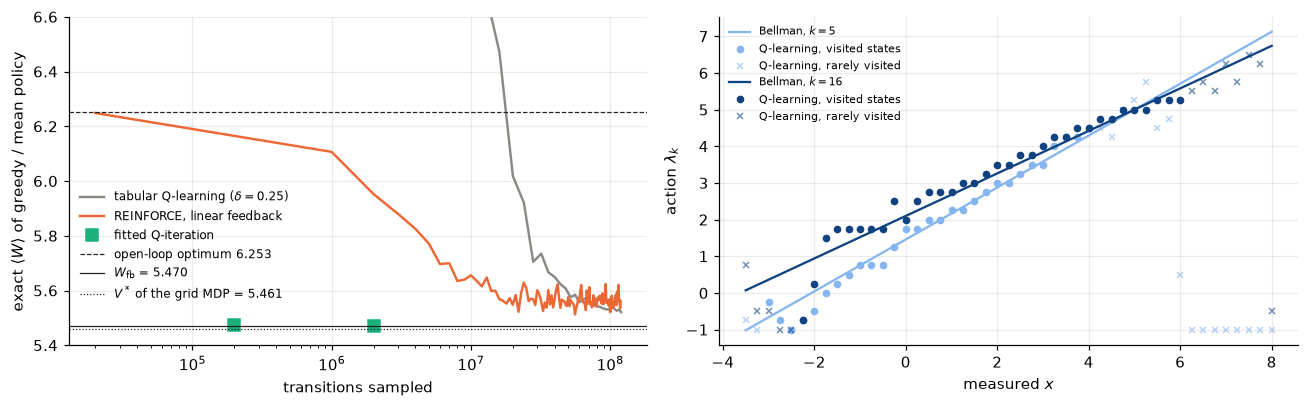

In [16]:
mdp, Qstar, Vstar = grids[0.25]
t0 = time.time()
Qq, nq, curve_q = agents.q_learning(mdp, 6_000_000, B=2000, eps=0.2, omega=0.7, seed=0, every=100)
print(f'Q-learning: {time.time() - t0:.1f} s, {6_000_000 * N:.1e} transitions')
pol_q, pol_star = agents.greedy_tabular(Qq, nq), Qstar.argmin(2)
W_q = trap.eval_tabular(pol_q, mdp)
frac = (W_star_N - W_q) / (W_star_N - Vstar)
p, occ = mdp['p0'].copy(), np.zeros(pol_star.shape)          # where the optimal policy actually goes
for kk in range(N):
    occ[kk] = p; p = p @ mdp['P'][np.arange(len(mdp['X'])), pol_star[kk]]
imp = occ > 1e-3
near = np.mean(np.abs(mdp['U'][pol_q[imp]] - mdp['U'][pol_star[imp]]) <= 0.25 + 1e-9)
well = np.broadcast_to(imp[:, :, None], Qq.shape) & (nq > 1000)
print(f'greedy policy: W = {W_q:.4f} in the discrete MDP (V* = {Vstar:.4f}, open loop {W_star_N:.4f})')
print(f'median |Q - Q*| on cells visited > 1000 times along the optimal path: {np.median(np.abs(Qq - Qstar)[well]):.4f}')
print(f'cells never visited: {np.mean(nq == 0):.1%} of {nq.size:,}')
Wc, dc, ec = paired_cost(trap.tabular_policy(pol_q, mdp))
print(f'in the continuous environment: W = {Wc:.4f}, cost vs W_fb {dc:.4f} ± {ec:.4f}')
check('greedy Q-learning policy is no better than V* (exact evaluation)', W_q >= Vstar - 1e-12)
check('Q-learning captures >= 85% of the discrete MDP gain over open loop', frac >= 0.85, f'{frac:.1%}')
check('greedy action within one grid step of optimal on >= 80% of visited states', near >= 0.8, f'{near:.1%}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogx(curve_q[:, 0] * N, curve_q[:, 1], color=C_LIN, label=r'tabular Q-learning ($\delta=0.25$)')
cf = fb_runs[0][2]
ax[0].semilogx(np.maximum(cf[:, 0], 1) * 1000 * N, cf[:, 1], color=C_FB, label='REINFORCE, linear feedback')
ax[0].semilogx([1e4 * N, 1e5 * N], [trap.eval_linear_policy(fqi[m], N, TF, DL) for m in (10_000, 100_000)], 's',
               color=C_FQI, ms=8, label='fitted Q-iteration')
for y, lab, ls in [(W_star_N, f'open-loop optimum {W_star_N:.3f}', '--'), (W_fb, rf'$W_{{\rm fb}}$ = {W_fb:.3f}', '-'),
                   (Vstar, rf'$V^*$ of the grid MDP = {Vstar:.3f}', ':')]:
    ax[0].axhline(y, color=C_INK, lw=0.8, ls=ls, label=lab)
ax[0].set_ylim(5.4, 6.6); ax[0].set_xlabel('transitions sampled'); ax[0].set_ylabel(r'exact $\langle W\rangle$ of greedy / mean policy')
ax[0].legend(fontsize=8, loc='lower left', bbox_to_anchor=(0.0, 0.1))
X_, U_ = mdp['X'], mdp['U']
for kk, col in [(4, '#86b6ef'), (15, '#104281')]:
    ax[1].plot(X_, G_fb[kk, 0] * X_ + G_fb[kk, 2], color=col, lw=1.5, label=f'Bellman, $k={kk + 1}$')
    m_ = imp[kk]
    ax[1].plot(X_[m_], U_[pol_q[kk, m_]], 'o', color=col, ms=4, label=f'Q-learning, visited states')
    ax[1].plot(X_[~m_], U_[pol_q[kk, ~m_]], 'x', color=col, ms=4, alpha=0.6, label='Q-learning, rarely visited')
ax[1].set_xlabel('measured $x$'); ax[1].set_ylabel(r'action $\lambda_k$'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

Q-learning gets there, but it takes about $10^8$ transitions to recover most of the gain. Fitted Q-iteration
reached 99.8% with $2\times10^6$. The difference is generalization. The table has about 29,000 independent
entries, while the fitted $Q$ has 10 numbers per step. Every cell of the table must be visited many times on its
own, and cells off the optimal path are barely learned at all: these are the crosses in the right panel. The
crosses pinned at $\lambda=-1$ are states that were never visited, where the greedy choice just falls back to the
first action.
REINFORCE sits in between. It has few parameters, but its gradient is noisy and carries no value function.

Even with infinite data, the tabular agent would stop at the discretization cost of its grid. That is the
textbook state/action-space picture, with the bill itemized.

**Not done here** (left from the brief's list): the stiffness protocol.

## Summary of checks

In [17]:
for name, ok in CHECKS: print(f"{'PASS' if ok else 'FAIL'}  {name}")
print(f"\n{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} passed")

PASS  <W> of constant speed matches exact (3 sigma)
PASS  Var W / 2<W> = 1 for constant speed (3 sigma, bootstrap)
PASS  <W> of optimal u* matches exact (3 sigma)
PASS  Var W / 2<W> = 1 for optimal u* (3 sigma, bootstrap)
PASS  <W> of random matches exact (3 sigma)
PASS  Var W / 2<W> = 1 for random (3 sigma, bootstrap)
PASS  Jarzynski <e^-W> = 1 at dl = 1 (3 sigma)
PASS  H is positive definite
PASS  u* has constant increments (1e-12)
PASS  W*_N >= W* for every N
PASS  W*_N - W* falls as N^-2
PASS  REINFORCE gradient (reward-to-go) is unbiased: chi2 < 99.9% point
PASS  REINFORCE gradient (full return) is unbiased: chi2 < 99.9% point
PASS  open-loop RL seed 0: Polyak excess < 1% of gap
PASS  open-loop RL seed 0: both jumps found (0.15)
PASS  open-loop RL seed 1: Polyak excess < 1% of gap
PASS  open-loop RL seed 1: both jumps found (0.15)
PASS  open-loop RL seed 2: Polyak excess < 1% of gap
PASS  open-loop RL seed 2: both jumps found (0.15)
PASS  open-loop RL seed 3: Polyak excess < 1% of